In [1]:
import os, glob
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_venn import venn3

In [2]:
pth = os.path.join('..', '..')
pth_feat = os.path.join(pth, 'data', 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'preprocessing', 'modules')

In [3]:
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src = lambda fn: os.path.split(fn)[1].replace('.csv', '')
feat_dict = {get_src(fn) : fn for fn in feat_fn if 'union' not in fn}
for src, fn in feat_dict.items():
    g = pd.read_csv(fn).mmusculus.copy()
    feat_dict[src] = set(g.to_numpy().tolist())

In [5]:
label_dict = {
    'GSE162534'         : 'PS',
    'GSE229103'         : 'NMP',
    'rRNAModifications' : 'CNC'}

In [4]:
c_dict = {
    'GSE162534'         : 'gold',
    'GSE229103'         : 'tab:cyan',
    'rRNAModifications' : 'orangered'}

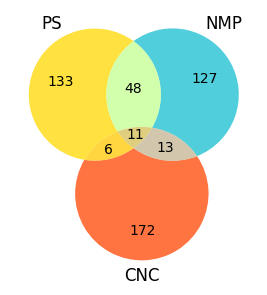

In [11]:
fig, ax = plt.subplots(1, 1, figsize = (3.5, 3.5))
labels = [label_dict[src] for src in feat_dict.keys()]
c = [c_dict[src] for src in feat_dict.keys()]
venn3(list(feat_dict.values()), labels, c, alpha = .75)
fn = os.path.join(pth_out, 'venn.pdf')
plt.savefig(fn, bbox_inches = 'tight')